# 04 — Perfiles de riesgo con K-Means

**Capa 3 — Procesamiento** · Aprendizaje no supervisado

**Objetivo:** agrupar las acciones según su **perfil de riesgo** con 4 variables: BSADF (crecimiento explosivo), momentum de 12 meses, volatilidad anual y beta contra el S&P 500. Así el comité ve, además del color del semáforo, *a qué tipo de comportamiento histórico se parece cada acción hoy*.

**Decisiones de diseño:**
- **Datos:** el panel histórico completo, con cada acción en cada semana que tenga las 4 variables. No se usan solo los 9 puntos de hoy, porque con 9 observaciones K-Means no tiene con qué aprender.
- **Estandarización:** cada variable a media 0 y desviación 1. Sin ella, la variable de mayor escala (momentum, que llega a +300%) dominaría las distancias.
- **Elección de k entre 2 y 6** con el método del codo y Silhouette, como en el Módulo 6. Semilla fija (42) para que el resultado sea reproducible.
- **Nombres** en palabras simples, a partir del centroide de cada grupo.

**Qué NO hace:** no cambia el semáforo, el backtest ni los KPIs. El perfil es **descriptivo**: agrega una columna a la hoja Variables del Excel.

**Entradas:** `data/processed/panel_semanal.csv`.
**Salidas:**
- `data/processed/perfiles_kmeans.json`: el modelo que usa `main.py` sin reentrenar. Se recalibra cada trimestre ejecutando este notebook.
- `outputs/figuras/kmeans_codo_silhouette.png` y `outputs/figuras/kmeans_bsadf_vs_volatilidad.png`.

Las funciones están en `src/perfiles.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config as C
from src import perfiles as P

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 200)
AZUL, NARANJA, TEAL, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#52514e"
DIR_FIGURAS = C.DIR_OUTPUTS / "figuras"
DIR_FIGURAS.mkdir(exist_ok=True)

panel = pd.read_csv(C.DIR_PROCESSED / "panel_semanal.csv", parse_dates=["fecha"])
datos = P.datos_historicos(panel)
print(f"Observaciones (acción × semana con las 4 variables): {len(datos):,}".replace(",", "."))
print(f"Periodo: {datos['fecha'].min():%d-%m-%Y} a {datos['fecha'].max():%d-%m-%Y}")
datos.groupby("ticker").agg(semanas=("fecha", "size"), desde=("fecha", "min")).T

Observaciones (acción × semana con las 4 variables): 9.971
Periodo: 24-12-1999 a 30-10-2026


ticker,AMD,AMZN,AVGO,GOOGL,META,MSFT,NVDA,ORCL,TSM
semanas,1402,1279,641,900,496,1402,1191,1402,1258
desde,1999-12-24 00:00:00,2002-05-03 00:00:00,2014-07-25 00:00:00,2009-08-07 00:00:00,2017-05-05 00:00:00,1999-12-24 00:00:00,2004-01-09 00:00:00,1999-12-24 00:00:00,2002-09-27 00:00:00


## 1. Estandarización

Las 4 variables tienen escalas muy distintas: el BSADF se mueve entre −3 y +3, la volatilidad entre 15% y 150%, el momentum puede superar +300% y la beta ronda 1-2. K-Means agrupa por **distancia**, así que sin estandarizar el momentum decidiría casi solo. Cada variable se lleva a media 0 y desviación 1 (z-score):

$$z = \frac{x - \text{media}}{\text{desviación}}$$

In [2]:
z, media, escala = P.estandarizar(datos)
pd.DataFrame({
    "media original": media, "desviación original": escala,
    "media estandarizada": z.mean(axis=0).round(6), "desviación estandarizada": z.std(axis=0).round(6),
}, index=P.VARIABLES).round(3)

,media original,desviación original,media estandarizada,desviación estandarizada
bsadf,-0.366,0.704,0.0,1.0
momentum_52s,0.325,0.619,0.0,1.0
volatilidad_anual,0.372,0.163,0.0,1.0
beta_104s,1.357,0.504,0.0,1.0


## 2. Elección de k: método del codo y Silhouette

- **Codo:** la **inercia** (suma de distancias al cuadrado de cada punto a su centroide) siempre baja al agregar grupos. Se busca el punto donde deja de bajar mucho.
- **Silhouette:** mide, entre −1 y 1, qué tan cerca está cada punto de su grupo frente al grupo vecino. Más alto es mejor.

Se prueban k = 2 a 6. El entrenamiento completo (`P.ajustar`) calcula ambas métricas, elige k y entrena el modelo final. Tarda menos de un minuto.

In [3]:
modelo = P.ajustar(panel)
tabla_k = pd.DataFrame(modelo["diagnostico_k"])
tabla_k["baja de inercia vs. k-1"] = tabla_k["inercia"].pct_change().map(lambda v: "" if pd.isna(v) else f"{v:.0%}")
tabla_k.round(3).set_index("k")

,inercia,silhouette,baja de inercia vs. k-1
k,,,
2,27921.743,0.385,
3,21183.901,0.374,-24%
4,17123.059,0.289,-19%
5,15280.439,0.291,-11%
6,13728.712,0.291,-10%


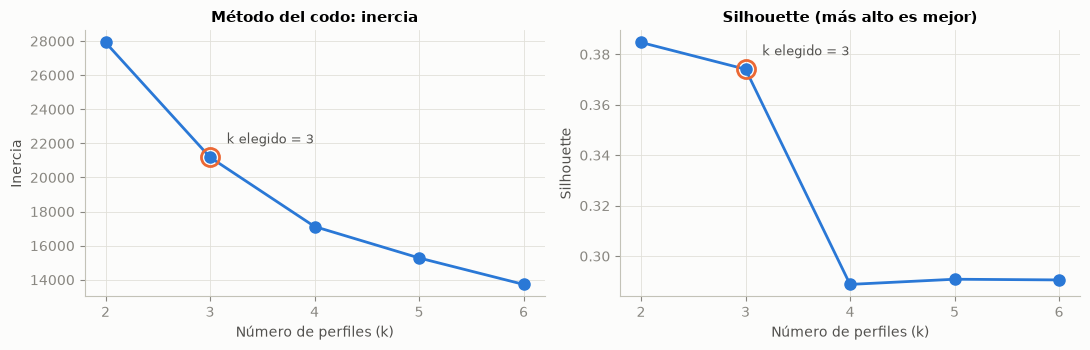

In [4]:
k_elegido = modelo["k"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, titulo in ((ax1, "inercia", "Método del codo: inercia"), (ax2, "silhouette", "Silhouette (más alto es mejor)")):
    ax.plot(tabla_k["k"], tabla_k[col], color=AZUL, lw=2, marker="o", ms=8)
    fila = tabla_k[tabla_k["k"] == k_elegido].iloc[0]
    ax.plot(k_elegido, fila[col], marker="o", ms=13, mfc="none", mec=NARANJA, mew=2)
    ax.annotate(f"k elegido = {k_elegido}", (k_elegido, fila[col]), xytext=(12, 10), textcoords="offset points",
                color=TINTA, fontsize=9)
    ax.set_title(titulo)
    ax.set_xlabel("Número de perfiles (k)")
    ax.set_xticks(tabla_k["k"])
ax1.set_ylabel("Inercia")
ax2.set_ylabel("Silhouette")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "kmeans_codo_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

**Justificación de k = 3:**
- **Silhouette:** k = 2 tiene la más alta (0,385), pero k = 3 queda prácticamente igual (0,374; diferencia de 0,011). Desde k = 4 cae con claridad, a ~0,29.
- **Codo:** pasar de 2 a 3 grupos reduce la inercia en 24%; de 3 a 4, en 19%, pero a costa de una Silhouette mucho peor. El codo útil está en 3.
- **Utilidad para el comité:** con k = 2, las semanas explosivas y las semanas volátiles quedan juntas en un solo grupo de "riesgo alto". Con k = 3 se separan, y para el comité no es lo mismo una acción en alza explosiva que una acción volátil y sensible al mercado sin alza.
- **Regla aplicada** (`config.TOLERANCIA_SILHOUETTE = 0,02`): el k más grande cuya Silhouette queda a menos de 0,02 de la máxima. **Transparencia:** la regla se fijó a la vista de la curva. Con la Silhouette máxima estricta, el resultado sería k = 2. Como los perfiles son descriptivos y no entran a ninguna regla de inversión ni KPI, esta elección no afecta los resultados validados.
- Una Silhouette de ~0,37 indica grupos **moderadamente** separados, algo habitual en datos financieros, que forman un continuo y no grupos nítidos.

## 3. Centroides y nombres de los perfiles

El nombre sale del centroide estandarizado, con una regla fija (`P.nombrar`): las variables con z ≥ 0,75 dan el nombre ("explosivo" = BSADF alto, "alcista" = momentum alto, "volátil", "sensible al mercado" = beta alta). Si ninguna supera el umbral y la volatilidad y la beta están bajo el promedio, el perfil es "estable".

In [5]:
centroides_z = pd.DataFrame(modelo["centroides_z"], columns=P.VARIABLES, index=modelo["nombres"]).round(2)
centroides_z["semanas en el grupo"] = modelo["tamanos"]
centroides_z["% del historial"] = (100 * np.array(modelo["tamanos"]) / sum(modelo["tamanos"])).round(1)
print("Centroides estandarizados (z):")
centroides_z

Centroides estandarizados (z):


,bsadf,momentum_52s,volatilidad_anual,beta_104s,semanas en el grupo,% del historial
volátil-sensible al mercado,-0.33,-0.46,1.21,1.19,2230,22.4
estable,-0.18,-0.21,-0.52,-0.51,6437,64.6
explosivo-alcista,1.44,1.81,0.52,0.49,1304,13.1


In [6]:
originales = P.centroides_originales(modelo)
pd.DataFrame({
    "BSADF": originales["bsadf"].round(2),
    "Momentum 12 meses": originales["momentum_52s"].map("{:.0%}".format),
    "Volatilidad anual": originales["volatilidad_anual"].map("{:.0%}".format),
    "Beta": originales["beta_104s"].round(2),
})

,BSADF,Momentum 12 meses,Volatilidad anual,Beta
volátil-sensible al mercado,-0.60,4%,57%,1.96
estable,-0.49,20%,29%,1.10
explosivo-alcista,0.65,145%,46%,1.61


**Cómo leer los perfiles** (en unidades originales):
- **Estable** (~65% del historial): BSADF bajo, momentum moderado, la volatilidad y la beta más bajas del universo. Es "estable" **en relación con estas 9 tecnológicas**, no en términos absolutos: su beta promedio sigue siendo cercana a 1,1.
- **Explosivo-alcista** (~13%): BSADF positivo y momentum de 12 meses muy alto (alrededor de +145%). Son las semanas de crecimiento explosivo, donde suele encenderse el semáforo.
- **Volátil-sensible al mercado** (~22%): alta volatilidad y beta cercana a 2, pero sin alza explosiva. Son acciones que se mueven mucho con el mercado, típicamente en caídas o correcciones.

## 4. Perfil actual de cada acción

Se asigna el centroide más cercano a la semana actual de cada acción, en el espacio estandarizado (equivalente a `KMeans.predict`).

In [7]:
actual = pd.read_csv(C.DIR_PROCESSED / "semaforo_actual.csv", parse_dates=["fecha"])
actual = actual[actual["ticker"].isin(C.UNIVERSO)].copy()
actual["perfil_riesgo"] = P.asignar(actual, modelo)
pd.DataFrame({
    "Semáforo": actual["semaforo"], "BSADF": actual["bsadf"].round(2),
    "Momentum 12 meses": actual["momentum_52s"].map("{:.0%}".format),
    "Volatilidad anual": actual["volatilidad_anual"].map("{:.0%}".format),
    "Beta": actual["beta_104s"].round(2), "Perfil de riesgo": actual["perfil_riesgo"],
}).set_index(actual["ticker"])

,Semáforo,BSADF,Momentum 12 meses,Volatilidad anual,Beta,Perfil de riesgo
ticker,,,,,,
TSM,rojo,0.40,37%,30%,1.45,estable
AMD,amarillo,0.01,97%,63%,1.89,explosivo-alcista
NVDA,verde,-0.21,1%,32%,1.85,estable
GOOGL,verde,-0.29,-0%,35%,1.24,estable
AVGO,verde,-0.46,-11%,45%,2.24,volátil-sensible al mercado
META,verde,-0.67,-5%,43%,1.65,volátil-sensible al mercado
MSFT,verde,-0.69,2%,36%,1.10,estable
AMZN,verde,-0.79,-2%,35%,1.51,estable
ORCL,verde,-1.12,-50%,61%,1.83,volátil-sensible al mercado


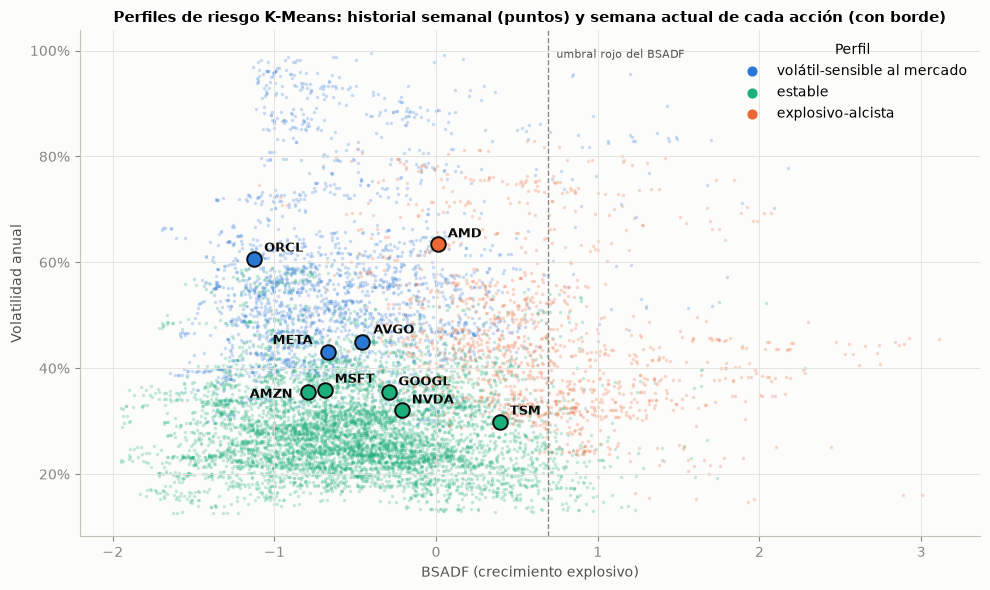

In [8]:
datos["perfil"] = P.asignar(datos, modelo)
colores = {nombre: {"estable": TEAL, "explosivo-alcista": NARANJA}.get(nombre, AZUL) for nombre in modelo["nombres"]}
desplazamiento = {"AMZN": (-42, -4), "META": (-40, 6), "AVGO": (8, 6)}     # evita etiquetas superpuestas
fig, ax = plt.subplots(figsize=(10, 6))
for nombre in modelo["nombres"]:
    g = datos[datos["perfil"] == nombre]
    ax.scatter(g["bsadf"], g["volatilidad_anual"], s=6, alpha=0.25, color=colores[nombre], lw=0)
    ax.scatter([], [], s=40, color=colores[nombre], label=nombre)     # entrada de leyenda opaca
for _, fila in actual.iterrows():
    ax.scatter(fila["bsadf"], fila["volatilidad_anual"], s=110, color=colores[fila["perfil_riesgo"]],
               edgecolor="#0b0b0b", lw=1.4, zorder=5)
    ax.annotate(fila["ticker"], (fila["bsadf"], fila["volatilidad_anual"]), xytext=desplazamiento.get(fila["ticker"], (7, 5)),
                textcoords="offset points", fontsize=9, fontweight="bold", color="#0b0b0b", zorder=6)
ax.axvline(actual["cv_bsadf_95"].iloc[0], color=GRIS, ls="--", lw=1)
ax.text(actual["cv_bsadf_95"].iloc[0] + 0.05, ax.get_ylim()[1] * 0.95, "umbral rojo del BSADF", color=TINTA, fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("BSADF (crecimiento explosivo)")
ax.set_ylabel("Volatilidad anual")
ax.set_title("Perfiles de riesgo K-Means: historial semanal (puntos) y semana actual de cada acción (con borde)")
ax.legend(title="Perfil", frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "kmeans_bsadf_vs_volatilidad.png", dpi=150, bbox_inches="tight")
plt.show()

**Cómo leerlo:**
- Cada punto es una acción en una semana. El perfil se calcula con las 4 variables; el gráfico muestra solo 2 (BSADF y volatilidad), por eso los grupos se superponen en parte.
- Los puntos con borde son la semana actual (30-10-2026).
- **TSM** está en rojo en el semáforo, pero su perfil es "estable". El semáforo mira los últimos 5 años: TSM tuvo un tramo explosivo y su rojo sigue vigente por persistencia. El perfil mira la semana actual: hoy su momentum (+37%) y su volatilidad están lejos de las semanas explosivas típicas (+145%). Las dos lecturas se complementan y **el perfil no reemplaza al semáforo**.
- **AMD** (amarillo) tiene hoy el perfil explosivo-alcista, por su alza de ~97% en 12 meses.

### Distribución de perfiles por acción en todo su historial

In [9]:
reparto = pd.crosstab(datos["ticker"], datos["perfil"], normalize="index").mul(100).round(0)
reparto[modelo["nombres"]]

perfil,volátil-sensible al mercado,estable,explosivo-alcista
ticker,,,
AMD,70.0,8.0,21.0
AMZN,12.0,77.0,11.0
AVGO,10.0,62.0,28.0
GOOGL,0.0,94.0,6.0
META,9.0,80.0,10.0
MSFT,3.0,96.0,1.0
NVDA,49.0,20.0,31.0
ORCL,13.0,82.0,5.0
TSM,14.0,76.0,11.0


## 5. Reproducibilidad y modelo guardado

Con la semilla fija, volver a entrenar da exactamente los mismos centroides. El modelo se guarda en `data/processed/perfiles_kmeans.json` (medias, desviaciones, centroides y nombres), en un formato legible que se versiona en Git. `main.py` lo lee cada semana y solo asigna perfiles, sin reentrenar. La recalibración trimestral (`docs/gobernanza.md`) consiste en ejecutar de nuevo este notebook.

In [10]:
otra_vez = P.ajustar(panel, k=modelo["k"])
print("Centroides idénticos al reentrenar:", np.allclose(otra_vez["centroides_z"], modelo["centroides_z"]))
P.guardar(modelo)
print(f"Modelo guardado: {C.RUTA_PERFILES.relative_to(RAIZ)} (k = {modelo['k']}, datos hasta {modelo['datos_hasta']})")

Centroides idénticos al reentrenar: True
Modelo guardado: data\processed\perfiles_kmeans.json (k = 3, datos hasta 2026-10-30)


## 6. Limitaciones

1. **Las observaciones semanales no son independientes.** La semana t de una acción se parece mucho a la t−1, porque el momentum, la volatilidad y la beta usan ventanas de 52 a 104 semanas que se traslapan. Por eso la Silhouette y los tamaños de los grupos sobrerrepresentan los periodos largos y estables, y no hay "9.971 observaciones independientes".
2. **Los perfiles son descriptivos, no predictivos.** Dicen a qué tipo de semana histórica se parece la actual. No dicen qué va a pasar ni la probabilidad de una caída: eso requeriría un modelo supervisado (por ejemplo, un random forest), que no forma parte de esta versión.
3. **Perfiles relativos al universo:** "estable" significa estable *entre estas 9 tecnológicas*, que en conjunto son más volátiles que el mercado.
4. **Sesgo de supervivencia:** el historial es de acciones que hoy son ganadoras. Las semanas "explosivo-alcista" que terminaron en quiebras no están en los datos.
5. **Separación moderada** (Silhouette ~0,37): una acción cerca del borde entre dos perfiles puede cambiar de perfil con un movimiento pequeño. La elección de k = 3 sobre k = 2 es un criterio de utilidad, documentado arriba.
6. **El modelo envejece:** se entrenó con datos hasta el 30-10-2026. Debe recalibrarse cada trimestre; entre recalibraciones, las semanas nuevas se asignan con los centroides vigentes.